# Random Forest: red wine quality (Low / Medium / High)

Same data contract, split, CV scheme and metric set as the logistic regression notebook, so the models can be compared fairly.

**Metrics.** Accuracy, balanced accuracy, macro-F1 (headline), per-class recall, quadratic weighted kappa (QWK), log loss, the confusion matrix,
CV mean ± SD, the majority-class baseline, feature importance, and the train vs CV gap.

| Step | What it does |
|---|---|
| 0 | Data contract, split, shared harness, majority-class baseline |
| 1 | Hyper-parameter search with 5 × 5 repeated CV on the training rows |
| 2 | Tuned vs default forest vs baseline (CV mean ± SD, paired comparison) |
| 3 | Train vs CV gap (how much the forest overfits) |
| 4 | Feature importance: impurity and permutation importance inside CV |
| 5 | Number of trees: does more trees help? |
| 6 | Final test evaluation, per-class recall, confusion matrix, error rate by grade, marginal cases |

In [1]:
import os, glob, time, hashlib, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_predict)
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, recall_score,
                             cohen_kappa_score, log_loss, confusion_matrix)
from sklearn.inspection import permutation_importance

# ---------------- Settings you may need to edit ----------------
N_TREES = 300          # trees per forest during tuning and in the final model
# ---------------------------------------------------------------

SEED = 42                                  # one seed for every random choice in the notebook
np.random.seed(SEED)                       # legacy global numpy RNG (used by some libraries)
rng = np.random.default_rng(SEED)          # our own generator for anything we sample ourselves
T_START = time.time()                      # to report total runtime at the end

N_SPLITS, N_REPEATS = 5, 5
# One CV object for the whole notebook. Because random_state is fixed, every model sees exactly the same
# 25 train/held-out folds, so fold-by-fold differences between models are fair (paired) comparisons.
RCV = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)

DATA_DIR = "."                             # the CSV sits in the same folder as this notebook
SPLIT_FILE = "split_indices.npz"           # shared with the other pairs, also next to the notebook
RES, FIG = "results", "figures"            # output folders, created automatically
for d in (RES, FIG):
    os.makedirs(d, exist_ok=True)


# Plot style: recessive grid, no top/right spines, 150 dpi on save.
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "font.size": 10, "axes.titlesize": 11})
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY = "#b8b7b2"                           # de-emphasised series
CLASS_NAMES = np.array(["Low", "Medium", "High"])
CLASS_COLORS = dict(zip(CLASS_NAMES, PALETTE[:3]))

def savefig(fig, name):
    """Save a figure as figures/<name> at 150 dpi and return the path."""
    path = os.path.join(FIG, name)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return path

def save_table(df, name, index=True):
    """Save a results table as results/<name>."""
    df.to_csv(os.path.join(RES, name), index=index)

print(f"numpy {np.__version__} | pandas {pd.__version__} | sklearn {sklearn.__version__}")

numpy 2.5.3 | pandas 3.0.5 | sklearn 1.9.1


In [2]:
# ---------------- Shared harness (stand-ins written to the team spec) ----------------
FEATURES = ["fixed acidity", "volatile acidity", "citric acid", "residual sugar", "chlorides",
            "free sulfur dioxide", "total sulfur dioxide", "density", "pH", "sulphates", "alcohol"]  # 11 inputs
METRICS = ["accuracy", "balanced_accuracy", "macro_f1", "qwk", "log_loss"]   # the main metric set
RECALLS = [f"recall_{c}" for c in CLASS_NAMES]

def _find_csv(data_dir=DATA_DIR):
    """Path of winequality-red.csv in the notebook's folder (tolerates e.g. 'winequality-red (1).csv')."""
    exact = os.path.join(data_dir, "winequality-red.csv")
    if os.path.exists(exact):
        return exact
    hits = sorted(glob.glob(os.path.join(data_dir, "*winequality-red*.csv")))
    if len(hits) == 1:
        return hits[0]
    raise FileNotFoundError(f"Expected winequality-red.csv in {os.path.abspath(data_dir)}; found {hits or 'nothing'}.")

def load_wine(data_dir=DATA_DIR):
    """Data contract (red only): exact duplicates dropped, 3-class target.

    Returns X (DataFrame, 11 features), y (0 Low / 1 Medium / 2 High), raw quality grade, raw row count.
    Duplicates keep their first occurrence in file order; the split depends on this order.
    """
    path = _find_csv(data_dir)
    print(f"Reading {path}")
    df = pd.read_csv(path, sep=";")                                  # UCI file: ';' separator, quoted headers
    assert list(df.columns) == FEATURES + ["quality"], "unexpected column names"
    assert df.notna().all().all(), "missing values found"
    n_raw = len(df)
    df = df.drop_duplicates(keep="first").reset_index(drop=True)     # exact duplicates over all 12 columns
    q = df["quality"].to_numpy()
    y = np.select([q <= 5, q == 6], [0, 1], default=2)               # <=5 Low, 6 Medium, >=7 High
    return df[FEATURES].astype(float), y, q, n_raw

def evaluate(name, y_true, proba):
    """Main metrics for an (n, 3) probability matrix. Macro-F1 is the headline metric."""
    y_true, proba = np.asarray(y_true), np.asarray(proba, dtype=float)
    assert proba.shape == (len(y_true), 3), "proba must be (n, 3)"
    pred = proba.argmax(axis=1)
    return {"model": name,
            "accuracy": accuracy_score(y_true, pred),
            "balanced_accuracy": balanced_accuracy_score(y_true, pred),
            "macro_f1": f1_score(y_true, pred, average="macro", zero_division=0),  # a never-predicted class scores F1 = 0
            "qwk": cohen_kappa_score(y_true, pred, weights="quadratic"),
            "log_loss": log_loss(y_true, proba, labels=[0, 1, 2])}

def class_recall(y_true, pred):
    """Recall for Low, Medium, High (share of each true class that is predicted correctly)."""
    return recall_score(y_true, pred, labels=[0, 1, 2], average=None, zero_division=0)

def ece_score(y_true, proba, n_bins=10):
    """Expected calibration error, 10 equal-width bins on the top probability (appendix only)."""
    conf = proba.max(axis=1)
    correct = proba.argmax(axis=1) == y_true
    b = np.minimum((conf * n_bins).astype(int), n_bins - 1)         # bin k covers [k/10, (k+1)/10); 1.0 goes in the last bin
    return sum((b == k).mean() * abs(correct[b == k].mean() - conf[b == k].mean())
               for k in range(n_bins) if (b == k).any())

def plot_confusion(name, y_true, proba, fname):
    """Confusion matrix with counts and row-normalised percentages."""
    cm = confusion_matrix(y_true, np.asarray(proba).argmax(axis=1), labels=[0, 1, 2])
    pct = cm / cm.sum(axis=1, keepdims=True)                         # recall per true class
    fig, ax = plt.subplots(figsize=(4.6, 4))
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    ax.grid(False)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]}\n{pct[i, j]:.0%}", ha="center", va="center",
                    color="white" if pct[i, j] > 0.55 else "#0b0b0b", fontsize=9)
    ax.set_xticks(range(3), CLASS_NAMES); ax.set_yticks(range(3), CLASS_NAMES)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
    ax.set_title(name)
    savefig(fig, fname); plt.show()
    return cm

# ---- Repeated-CV helpers (used for every model comparison) ----
def repeated_cv(make_model, X, y, name):
    """Fit make_model() on each of the 25 RCV training folds and score the held-out fold.

    Returns (per-fold metrics DataFrame, out-of-fold probabilities of shape (N_REPEATS, n, 3)).
    Each wine is held out exactly once per repeat, so oof[r] is a complete set of honest predictions.
    """
    rows, oof = [], np.full((N_REPEATS, len(y), 3), np.nan)
    for k, (tr, ho) in enumerate(RCV.split(X, y)):                   # splits come repeat by repeat, 5 folds each
        model = make_model().fit(X.iloc[tr], y[tr])
        P = model.predict_proba(X.iloc[ho])
        oof[k // N_SPLITS, ho] = P
        m = evaluate(name, y[ho], P)
        m.update(dict(zip(RECALLS, class_recall(y[ho], P.argmax(axis=1)))))
        m.update({"ece": ece_score(y[ho], P), "repeat": k // N_SPLITS, "fold": k % N_SPLITS})
        rows.append(m)
    return pd.DataFrame(rows), oof

def cv_summary(folds, cols=METRICS + RECALLS):
    """Mean and SD over the 25 folds, as a two-column table."""
    return folds[cols].agg(["mean", "std"]).T

def mean_sd(folds, col):
    return f"{folds[col].mean():.3f} ± {folds[col].std():.3f}"

def paired(folds_a, folds_b, col="macro_f1"):
    """Fold-by-fold difference a - b on the same 25 folds: mean, SD, and how many folds a wins."""
    d = folds_a[col].to_numpy() - folds_b[col].to_numpy()
    return {"mean_diff": d.mean(), "sd_diff": d.std(ddof=1), "folds_a_better": int((d > 0).sum()), "n_folds": len(d)}

# ---- Marginal-case helpers (team definition: m(x) = p_top - p_second, marginal when m < 0.2) ----
MARGIN_EDGES = [0, 0.1, 0.2, 0.4, 0.6, 1.0 + 1e-9]                  # last bin is closed at 1
MARGIN_LABELS = ["[0,0.1)", "[0.1,0.2)", "[0.2,0.4)", "[0.4,0.6)", "[0.6,1]"]

def prob_margin(proba):
    s = np.sort(np.asarray(proba), axis=1)
    return s[:, -1] - s[:, -2]

def marginal_report(y_true, proba, thr=0.2):
    """Summary dict + per-bin accuracy table for the team's marginal-case analysis."""
    y_true = np.asarray(y_true)
    m, pred = prob_margin(proba), np.asarray(proba).argmax(axis=1)
    correct, marg = pred == y_true, m < thr
    nanmean = lambda a: a.mean() if a.size else np.nan                # guard against empty groups
    summary = {"n": len(y_true), "n_marginal": int(marg.sum()), "share_marginal": marg.mean(),
               "acc_marginal": nanmean(correct[marg]), "acc_confident": nanmean(correct[~marg]),
               "share_marginal_true_medium": nanmean(y_true[marg] == 1),
               "share_marginal_pred_medium": nanmean(pred[marg] == 1)}
    bins = pd.cut(m, MARGIN_EDGES, right=False, labels=MARGIN_LABELS)
    table = (pd.DataFrame({"bin": bins, "correct": correct})
             .groupby("bin", observed=False)["correct"].agg(n="size", accuracy="mean"))
    table["share"] = table["n"] / len(y_true)
    return summary, table

# ---- Error rate by original quality grade (3 to 8) ----
GRADES = np.arange(3, 9)
GRADE_CLASS = {3: "Low", 4: "Low", 5: "Low", 6: "Medium", 7: "High", 8: "High"}

def error_by_grade(q, y_true, pred):
    df = pd.DataFrame({"grade": q, "error": np.asarray(pred) != np.asarray(y_true)})
    return df.groupby("grade")["error"].agg(n="size", error_rate="mean").reindex(GRADES)


In [3]:
X_all, y_all, q_all, n_raw = load_wine()
assert n_raw == 1599, f"expected 1,599 raw red rows, got {n_raw}"
assert len(X_all) == 1359, f"expected 1,359 rows after de-duplication, got {len(X_all)}"
N_TR, N_VA, N_TE = 951, 204, 204

if os.path.exists(SPLIT_FILE):                                       # a shared split file wins if it is the red-only one
    z = np.load(SPLIT_FILE)
    pick = lambda key: z[[k for k in z.files if key in k.lower()][0]]
    idx_tr, idx_va, idx_te = pick("train"), pick("val"), pick("test")
    sizes = (len(idx_tr), len(idx_va), len(idx_te))
    if sizes != (N_TR, N_VA, N_TE) or max(idx_tr.max(), idx_va.max(), idx_te.max()) >= len(X_all):
        raise ValueError(f"{SPLIT_FILE} in this folder has {sizes[0]} / {sizes[1]} / {sizes[2]} rows, so it is not the "
                         f"red-only split (expected {N_TR} / {N_VA} / {N_TE}). It is probably the old red + white file: "
                         "rename or delete it and rerun, and the notebook will write a red-only one.")
    split_source = f"loaded from {SPLIT_FILE}"
else:
    # 70 / 30 first, then the 30 % is halved: first half = validation, second half = test.
    idx_all = np.arange(len(y_all))
    idx_tr, idx_tmp = train_test_split(idx_all, test_size=0.30, stratify=y_all, random_state=SEED)
    idx_va, idx_te = train_test_split(idx_tmp, test_size=0.50, stratify=y_all[idx_tmp], random_state=SEED)
    np.savez(SPLIT_FILE, train=idx_tr, val=idx_va, test=idx_te)      # write it so every pair can load identical rows
    split_source = f"generated (70/30 then 50/50, random_state={SEED}) and saved to {SPLIT_FILE}"
assert (len(idx_tr), len(idx_va), len(idx_te)) == (N_TR, N_VA, N_TE)
assert len(np.union1d(np.union1d(idx_tr, idx_va), idx_te)) == len(X_all)   # disjoint and complete

# Short fingerprint of the test rows: every pair should print the same string.
fingerprint = hashlib.md5(np.sort(idx_te).astype(np.int64).tobytes()).hexdigest()[:10]

X_tr, y_tr, q_tr = X_all.iloc[idx_tr].reset_index(drop=True), y_all[idx_tr], q_all[idx_tr]
X_va, y_va = X_all.iloc[idx_va].reset_index(drop=True), y_all[idx_va]
# NOTE: no X_te / y_te here on purpose. The test rows are built in step 8 only.

shares = pd.DataFrame({s: pd.Series(y).value_counts(normalize=True).reindex([0, 1, 2]).values
                       for s, y in [("all", y_all), ("train", y_tr), ("val", y_va), ("test", y_all[idx_te])]},
                      index=CLASS_NAMES)
grades = pd.DataFrame({s: pd.Series(q).value_counts().reindex(GRADES, fill_value=0)
                       for s, q in [("all", q_all), ("train", q_tr), ("val", q_all[idx_va]), ("test", q_all[idx_te])]})
grades.index.name = "grade"
save_table(shares.round(4), "rf_step0_class_shares.csv")
save_table(grades, "rf_step0_grade_counts.csv")
save_table(pd.DataFrame({"value": [split_source, fingerprint, N_TR, N_VA, N_TE]},
                        index=["split_source", "test_fingerprint", "n_train", "n_val", "n_test"]), "rf_step0_split_info.csv")
print(shares.round(3)); print("\nWines per quality grade:\n" + grades.to_string())
print(f"\nSplit {split_source}: {N_TR} / {N_VA} / {N_TE} rows; test fingerprint {fingerprint}.")
print(f"Summary: the red-only contract holds (1,599 -> 1,359 rows, 11 features), and the stratified split keeps class "
      f"shares equal across splits. The test set has only {int((y_all[idx_te] == 2).sum())} High wines and "
      f"{grades.loc[3, 'test']} / {grades.loc[8, 'test']} wines of grade 3 / 8, which is why per-class and per-grade results "
      f"are also reported from repeated CV on the {N_TR} training wines.")

Reading ./winequality-red.csv
          all  train    val   test
Low     0.471  0.471  0.471  0.471
Medium  0.394  0.393  0.392  0.397
High    0.135  0.136  0.137  0.132

Wines per quality grade:
       all  train  val  test
grade                       
3       10      5    2     3
4       53     35    6    12
5      577    408   88    81
6      535    374   80    81
7      167    117   24    26
8       17     12    4     1

Split generated (70/30 then 50/50, random_state=42) and saved to split_indices.npz: 951 / 204 / 204 rows; test fingerprint a963514c99.
Summary: the red-only contract holds (1,599 -> 1,359 rows, 11 features), and the stratified split keeps class shares equal across splits. The test set has only 27 High wines and 3 / 1 wines of grade 3 / 8, which is why per-class and per-grade results are also reported from repeated CV on the 951 training wines.


## Step 0: majority-class baseline

Always predicts the most common class (Low) and gives every wine the training class shares as probabilities.
Any useful model must beat it.

In [4]:
make_dummy = lambda: DummyClassifier(strategy="prior")             # predict(): majority class; predict_proba(): class shares
cv_dummy, _ = repeated_cv(make_dummy, X_tr, y_tr, "Majority class")
base_tab = cv_summary(cv_dummy)
save_table(base_tab.round(4), "rf_step0_majority_baseline_cv.csv")
print(base_tab.round(3).to_string())
print(f"Summary: always guessing Low gives accuracy {mean_sd(cv_dummy, 'accuracy')}, macro-F1 "
      f"{mean_sd(cv_dummy, 'macro_f1')} and QWK {cv_dummy['qwk'].mean():.2f}, with log loss {cv_dummy['log_loss'].mean():.3f}. "
      f"Balanced accuracy is exactly 1/3 because it recalls one class perfectly and the other two not at all.")

                    mean    std
accuracy           0.471  0.002
balanced_accuracy  0.333  0.000
macro_f1           0.213  0.001
qwk                0.000  0.000
log_loss           0.993  0.002
recall_Low         1.000  0.000
recall_Medium      0.000  0.000
recall_High        0.000  0.000
Summary: always guessing Low gives accuracy 0.471 ± 0.002, macro-F1 0.213 ± 0.001 and QWK 0.00, with log loss 0.993. Balanced accuracy is exactly 1/3 because it recalls one class perfectly and the other two not at all.


## Step 1: hyper-parameter search (training rows only, 5 × 5 repeated CV)

Selection criterion is the CV mean macro-F1, the team's headline metric. `class_weight='balanced_subsample'` is included because High is only about 14% of wines. The validation and test rows are not touched here.

In [5]:
make_rf = lambda **kw: RandomForestClassifier(n_estimators=N_TREES, random_state=SEED, n_jobs=-1, **kw)

grid = [dict(max_depth=d, min_samples_leaf=l, max_features=f, class_weight=w)
        for d in (None, 10) for l in (1, 3, 5) for f in ("sqrt", 0.5) for w in (None, "balanced_subsample")]
rows, grid_folds = [], {}
for i, p in enumerate(grid):
    folds, _ = repeated_cv(lambda p=p: make_rf(**p), X_tr, y_tr, f"cfg{i}")
    grid_folds[i] = folds
    rows.append({**{k: str(v) for k, v in p.items()}, "cv_macro_f1": folds["macro_f1"].mean(),
                 "cv_macro_f1_sd": folds["macro_f1"].std(), "cv_accuracy": folds["accuracy"].mean(),
                 "cv_qwk": folds["qwk"].mean(), "cv_log_loss": folds["log_loss"].mean()})
tune = pd.DataFrame(rows).sort_values("cv_macro_f1", ascending=False).reset_index(drop=True)
save_table(tune.round(4), "rf_step1_grid_search.csv", index=False)
print(tune.head(8).round(3).to_string())
best_i = int(max(grid_folds, key=lambda i: grid_folds[i]["macro_f1"].mean()))
best_params = grid[best_i]
print(f"\nBest by CV macro-F1: {best_params}")
print(f"Summary: {len(grid)} settings were compared on the same 25 folds. The best reaches CV macro-F1 "
      f"{mean_sd(grid_folds[best_i], 'macro_f1')}; the spread between the best and the 8th setting is only "
      f"{tune['cv_macro_f1'].iloc[0] - tune['cv_macro_f1'].iloc[7]:.3f}, so many settings are statistically close.")

  max_depth min_samples_leaf max_features        class_weight  cv_macro_f1  cv_macro_f1_sd  cv_accuracy  cv_qwk  cv_log_loss
0      None                5          0.5  balanced_subsample        0.605           0.045        0.632   0.589        0.771
1        10                1         sqrt  balanced_subsample        0.604           0.050        0.643   0.578        0.758
2      None                5         sqrt  balanced_subsample        0.603           0.042        0.630   0.587        0.774
3        10                5         sqrt  balanced_subsample        0.603           0.039        0.630   0.588        0.776
4        10                5          0.5  balanced_subsample        0.602           0.042        0.629   0.586        0.772
5        10                3          0.5  balanced_subsample        0.602           0.047        0.635   0.585        0.765
6      None                1         sqrt  balanced_subsample        0.600           0.043        0.648   0.568        0.758


## Step 2: tuned vs default forest vs baseline

The default forest is sklearn's defaults (unlimited depth, `max_features='sqrt'`, no class weights). The paired difference is computed fold by fold on the same 25 folds.

                  Majority class        RF default        RF tuned       
                            mean    std       mean    std     mean    std
accuracy                   0.471  0.002      0.641  0.035    0.632  0.037
balanced_accuracy          0.333  0.000      0.580  0.039    0.612  0.048
macro_f1                   0.213  0.001      0.595  0.044    0.605  0.045
qwk                        0.000  0.000      0.559  0.051    0.589  0.053
log_loss                   0.993  0.002      0.761  0.037    0.771  0.041
recall_Low                 1.000  0.000      0.763  0.046    0.734  0.042
recall_Medium              0.000  0.000      0.580  0.048    0.533  0.057
recall_High                0.000  0.000      0.397  0.080    0.570  0.123

Paired (macro-F1, tuned minus default): {'mean_diff': np.float64(0.0097), 'sd_diff': np.float64(0.035), 'folds_a_better': 16, 'n_folds': 25}
Paired (macro-F1, tuned minus baseline): {'mean_diff': np.float64(0.3912), 'sd_diff': np.float64(0.045), 'folds_a_bett

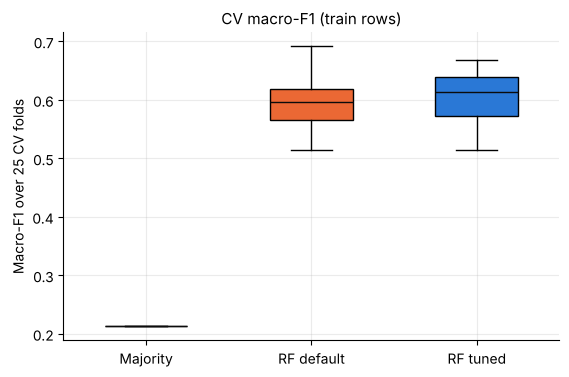

Summary: CV macro-F1 is 0.605 ± 0.045 for the tuned forest, 0.595 ± 0.044 for the default forest and 0.213 ± 0.001 for the majority baseline. Tuning changes macro-F1 by +0.010 (tuned wins 16 of 25 folds).


In [6]:
cv_def, oof_def = repeated_cv(lambda: make_rf(), X_tr, y_tr, "RF default")
cv_rf, oof_rf = repeated_cv(lambda: make_rf(**best_params), X_tr, y_tr, "RF tuned")
cmp_tab = pd.concat({"Majority class": cv_summary(cv_dummy), "RF default": cv_summary(cv_def), "RF tuned": cv_summary(cv_rf)}, axis=1)
save_table(cmp_tab.round(4), "rf_step2_cv_comparison.csv")
print(cmp_tab.round(3).to_string())
p_tune = paired(cv_rf, cv_def); p_base = paired(cv_rf, cv_dummy)
save_table(pd.DataFrame({"tuned_minus_default": p_tune, "tuned_minus_baseline": p_base}).round(4), "rf_step2_paired.csv")
print("\nPaired (macro-F1, tuned minus default):", {k: round(v, 4) for k, v in p_tune.items()})
print("Paired (macro-F1, tuned minus baseline):", {k: round(v, 4) for k, v in p_base.items()})

fig, ax = plt.subplots(figsize=(6.4, 4))
for j, (nm, f) in enumerate([("Majority", cv_dummy), ("RF default", cv_def), ("RF tuned", cv_rf)]):
    ax.boxplot(f["macro_f1"], positions=[j], widths=0.5, patch_artist=True,
               boxprops=dict(facecolor=[GREY, PALETTE[1], PALETTE[0]][j]), medianprops=dict(color="#0b0b0b"))
ax.set_xticks(range(3), ["Majority", "RF default", "RF tuned"]); ax.set_ylabel("Macro-F1 over 25 CV folds")
ax.set_title("CV macro-F1 (train rows)"); savefig(fig, "rf_step2_cv_macro_f1.png"); plt.show()
print(f"Summary: CV macro-F1 is {mean_sd(cv_rf, 'macro_f1')} for the tuned forest, {mean_sd(cv_def, 'macro_f1')} for the default forest and "
      f"{mean_sd(cv_dummy, 'macro_f1')} for the majority baseline. Tuning changes macro-F1 by {p_tune['mean_diff']:+.3f} "
      f"(tuned wins {p_tune['folds_a_better']} of {p_tune['n_folds']} folds).")

## Step 3: train vs CV gap

Train score = the tuned forest fitted on all 951 training rows and scored on those same rows. CV score = mean over the 25 held-out folds. A large gap means the forest memorises the training data.

In [7]:
rf_fit = make_rf(**best_params).fit(X_tr, y_tr)
train_res = evaluate("train", y_tr, rf_fit.predict_proba(X_tr))
train_res.update(dict(zip(RECALLS, class_recall(y_tr, rf_fit.predict(X_tr)))))
gap_tab = pd.DataFrame({"train": {k: train_res[k] for k in METRICS + RECALLS},
                        "cv_mean": cv_rf[METRICS + RECALLS].mean(), "cv_sd": cv_rf[METRICS + RECALLS].std()})
gap_tab["gap_train_minus_cv"] = gap_tab["train"] - gap_tab["cv_mean"]
gap_tab.loc["log_loss", "gap_train_minus_cv"] = gap_tab.loc["log_loss", "cv_mean"] - gap_tab.loc["log_loss", "train"]   # lower is better, so flip sign
save_table(gap_tab.round(4), "rf_step3_train_vs_cv_gap.csv")
print(gap_tab.round(3).to_string())
print("(log_loss gap is CV minus train, so a positive number always means 'worse out of sample'.)")
oob = RandomForestClassifier(n_estimators=N_TREES, random_state=SEED, n_jobs=-1, oob_score=True, **best_params).fit(X_tr, y_tr)
print(f"\nOut-of-bag accuracy: {oob.oob_score_:.3f} (a free CV-like estimate from the bootstrap).")
gap_f1 = gap_tab.loc["macro_f1", "gap_train_minus_cv"]
print(f"Summary: the forest scores macro-F1 {gap_tab.loc['macro_f1', 'train']:.3f} on its own training rows but "
      f"{gap_tab.loc['macro_f1', 'cv_mean']:.3f} in CV, a gap of {gap_f1:.3f}. Forests always fit their own training rows better than new rows, "
      f"because each tree has seen about two thirds of them; min_samples_leaf={best_params['min_samples_leaf']} limits this but does not remove it. "
      f"The CV number (and the out-of-bag accuracy {oob.oob_score_:.3f}) is the honest estimate of performance on new wines.")

                   train  cv_mean  cv_sd  gap_train_minus_cv
accuracy           0.896    0.632  0.037               0.264
balanced_accuracy  0.910    0.612  0.048               0.298
macro_f1           0.893    0.605  0.045               0.288
qwk                0.870    0.589  0.053               0.282
log_loss           0.464    0.771  0.041               0.307
recall_Low         0.902    0.734  0.042               0.168
recall_Medium      0.866    0.533  0.057               0.334
recall_High        0.961    0.570  0.123               0.391
(log_loss gap is CV minus train, so a positive number always means 'worse out of sample'.)



Out-of-bag accuracy: 0.627 (a free CV-like estimate from the bootstrap).
Summary: the forest scores macro-F1 0.893 on its own training rows but 0.605 in CV, a gap of 0.288. Forests always fit their own training rows better than new rows, because each tree has seen about two thirds of them; min_samples_leaf=5 limits this but does not remove it. The CV number (and the out-of-bag accuracy 0.627) is the honest estimate of performance on new wines.


## Step 4: feature importance

Two views. **Impurity importance** is how much each feature reduces Gini impurity across the trees (fast, but biased toward features with many distinct values). **Permutation importance** is the drop in macro-F1 when one feature's values are shuffled on *held-out* rows, computed inside each of the 25 CV folds, so it measures what the feature contributes out of sample.

                      impurity_mean  impurity_sd  permutation_mean  permutation_sd  impurity_rank  permutation_rank
alcohol                      0.2459       0.0104            0.1465          0.0388              1                 1
sulphates                    0.1421       0.0149            0.0661          0.0321              2                 2
volatile acidity             0.1181       0.0096            0.0321          0.0243              3                 3
total sulfur dioxide         0.0780       0.0046            0.0072          0.0150              4                 6
density                      0.0736       0.0053            0.0113          0.0162              5                 4
citric acid                  0.0720       0.0046            0.0069          0.0135              6                 8
fixed acidity                0.0663       0.0053            0.0102          0.0146              7                 5
chlorides                    0.0608       0.0038            0.0054      

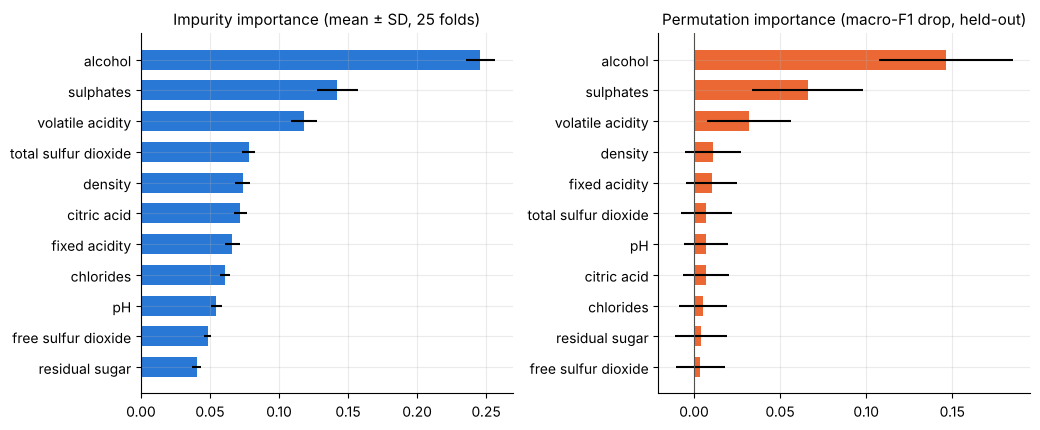

Summary: the top three features by permutation importance are alcohol, sulphates, volatile acidity; shuffling the top one costs 0.147 macro-F1. The other eight each cost at most 0.011, and for 8 of them the fold-to-fold SD is larger than the mean, so their ranking is not reliable. Impurity importance spreads weight more evenly because it favours features with many distinct values.


In [8]:
perm_rows, imp_rows = [], []
for k, (tr, ho) in enumerate(RCV.split(X_tr, y_tr)):
    m = make_rf(**best_params).fit(X_tr.iloc[tr], y_tr[tr])
    imp_rows.append(m.feature_importances_)
    pi = permutation_importance(m, X_tr.iloc[ho], y_tr[ho], scoring="f1_macro", n_repeats=5, random_state=SEED, n_jobs=1)
    perm_rows.append(pi.importances_mean)
fi = pd.DataFrame({"impurity_mean": np.mean(imp_rows, axis=0), "impurity_sd": np.std(imp_rows, axis=0, ddof=1),
                   "permutation_mean": np.mean(perm_rows, axis=0), "permutation_sd": np.std(perm_rows, axis=0, ddof=1)},
                  index=FEATURES).sort_values("impurity_mean", ascending=False)
fi["impurity_rank"] = fi["impurity_mean"].rank(ascending=False).astype(int)
fi["permutation_rank"] = fi["permutation_mean"].rank(ascending=False).astype(int)
save_table(fi.round(4), "rf_step4_feature_importance.csv")
print(fi.round(4).to_string())

fig, axs = plt.subplots(1, 2, figsize=(10.5, 4.4))
o = fi.sort_values("impurity_mean")
axs[0].barh(o.index, o["impurity_mean"], xerr=o["impurity_sd"], color=PALETTE[0], height=0.65)
axs[0].set_title("Impurity importance (mean ± SD, 25 folds)")
o = fi.sort_values("permutation_mean")
axs[1].barh(o.index, o["permutation_mean"], xerr=o["permutation_sd"], color=PALETTE[1], height=0.65)
axs[1].axvline(0, color="#52514e", lw=0.8)
axs[1].set_title("Permutation importance (macro-F1 drop, held-out)")
fig.tight_layout(); savefig(fig, "rf_step4_feature_importance.png"); plt.show()
top = fi["permutation_mean"].sort_values(ascending=False)
rest = top.iloc[3:]
n_noisy = int((rest < fi.loc[rest.index, "permutation_sd"]).sum())
print(f"Summary: the top three features by permutation importance are {', '.join(top.index[:3])}; shuffling the top one costs {top.iloc[0]:.3f} macro-F1. "
      f"The other eight each cost at most {rest.max():.3f}, and for {n_noisy} of them the fold-to-fold SD is larger than the mean, "
      f"so their ranking is not reliable. Impurity importance spreads weight more evenly because it favours features with many distinct values.")

## Step 5: number of trees

CV macro-F1 as the forest grows (same 25 folds). Variance falls as trees are added, but after a point there is nothing left to gain.

         cv_macro_f1  cv_macro_f1_sd  cv_log_loss
n_trees                                          
10             0.581           0.041        0.987
25             0.595           0.047        0.808
50             0.595           0.045        0.779
100            0.602           0.042        0.776
200            0.602           0.042        0.772
300            0.605           0.045        0.771
500            0.600           0.042        0.771


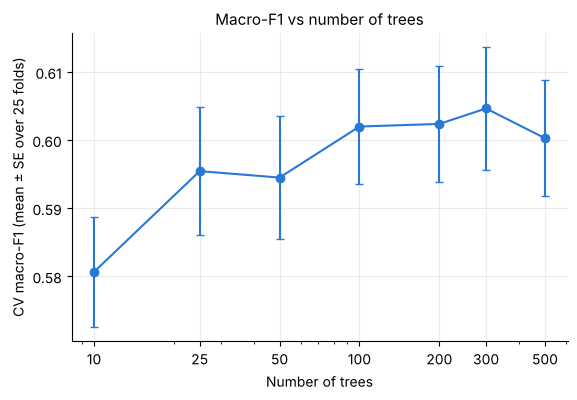

Summary: macro-F1 goes from 0.581 with 10 trees to 0.600 with 500. The curve is flat from roughly 100 trees on, so 300 trees is enough.


In [9]:
tree_counts = [10, 25, 50, 100, 200, 300, 500]
rows = []
for n in tree_counts:
    f, _ = repeated_cv(lambda n=n: RandomForestClassifier(n_estimators=n, random_state=SEED, n_jobs=-1, **best_params), X_tr, y_tr, f"{n} trees")
    rows.append({"n_trees": n, "cv_macro_f1": f["macro_f1"].mean(), "cv_macro_f1_sd": f["macro_f1"].std(),
                 "cv_log_loss": f["log_loss"].mean()})
trees = pd.DataFrame(rows).set_index("n_trees")
save_table(trees.round(4), "rf_step5_n_trees.csv")
print(trees.round(3).to_string())
fig, ax = plt.subplots(figsize=(6.4, 4))
ax.errorbar(trees.index, trees["cv_macro_f1"], yerr=trees["cv_macro_f1_sd"] / np.sqrt(25), marker="o", color=PALETTE[0], capsize=3)
ax.set_xscale("log"); ax.set_xticks(tree_counts, [str(n) for n in tree_counts])
ax.set_xlabel("Number of trees"); ax.set_ylabel("CV macro-F1 (mean ± SE over 25 folds)")
ax.set_title("Macro-F1 vs number of trees"); savefig(fig, "rf_step5_n_trees.png"); plt.show()
print(f"Summary: macro-F1 goes from {trees['cv_macro_f1'].iloc[0]:.3f} with 10 trees to {trees['cv_macro_f1'].iloc[-1]:.3f} with 500. "
      f"The curve is flat from roughly 100 trees on, so {N_TREES} trees is enough.")

## Step 6: validation check and final test evaluation

The forest is fitted on the 951 training rows. The 204 validation rows are a secondary check. The 204 test rows are used here for the first and only time.

Validation check (204 wines, secondary):
          accuracy  balanced_accuracy  macro_f1    qwk  log_loss
model                                                           
RF tuned     0.657              0.662     0.638  0.639     0.731

TEST metrics:
                accuracy  balanced_accuracy  macro_f1    qwk  log_loss
model                                                                 
Random Forest      0.613              0.571     0.558  0.558     0.771
Majority class     0.471              0.333     0.213  0.000     0.989


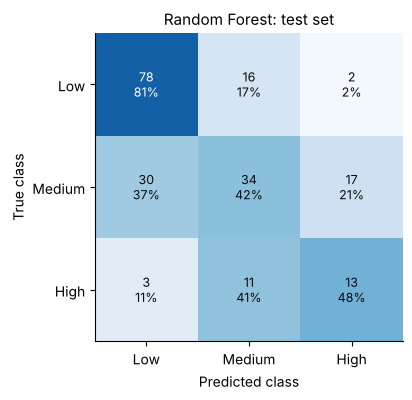


Recall per class:
        n_test  recall_test  recall_cv_mean  recall_cv_sd  recall_majority_baseline
Low         96        0.812           0.734         0.042                       1.0
Medium      81        0.420           0.533         0.057                       0.0
High        27        0.481           0.570         0.123                       0.0
Summary: on test the forest reaches macro-F1 0.558 vs 0.213 for the majority baseline (CV: 0.605 ± 0.045), QWK 0.558 and log loss 0.771. High recall is 48% on only 27 test wines; the CV estimate is 57% ± 12%.


In [10]:
final_model = make_rf(**best_params).fit(X_tr, y_tr)
val_res = pd.DataFrame([evaluate("RF tuned", y_va, final_model.predict_proba(X_va))]).set_index("model")
save_table(val_res.round(4), "rf_step6_validation_check.csv")
print("Validation check (204 wines, secondary):\n" + val_res.round(3).to_string())

# ---------- FIRST AND ONLY USE OF THE TEST ROWS ----------
X_te = X_all.iloc[idx_te].reset_index(drop=True)
y_te, q_te = y_all[idx_te], q_all[idx_te]
P_te = final_model.predict_proba(X_te)
dummy = make_dummy().fit(X_tr, y_tr)
test_res = pd.DataFrame([evaluate("Random Forest", y_te, P_te),
                         evaluate("Majority class", y_te, dummy.predict_proba(X_te))]).set_index("model")
save_table(test_res.round(4), "rf_step6_test_metrics.csv")
print("\nTEST metrics:\n" + test_res.round(3).to_string())
cm = plot_confusion("Random Forest: test set", y_te, P_te, "rf_step6_confusion_test.png")
save_table(pd.DataFrame(cm, index=[f"true_{c}" for c in CLASS_NAMES], columns=[f"pred_{c}" for c in CLASS_NAMES]), "rf_step6_confusion_test.csv")

recall_tab = pd.DataFrame({"n_test": np.bincount(y_te, minlength=3),
                           "recall_test": class_recall(y_te, P_te.argmax(axis=1)),
                           "recall_cv_mean": cv_rf[RECALLS].mean().to_numpy(),
                           "recall_cv_sd": cv_rf[RECALLS].std().to_numpy(),
                           "recall_majority_baseline": class_recall(y_te, dummy.predict(X_te))}, index=CLASS_NAMES)
save_table(recall_tab.round(4), "rf_step6_recall_per_class.csv")
print("\nRecall per class:\n" + recall_tab.round(3).to_string())
print(f"Summary: on test the forest reaches macro-F1 {test_res.loc['Random Forest', 'macro_f1']:.3f} vs "
      f"{test_res.loc['Majority class', 'macro_f1']:.3f} for the majority baseline (CV: {mean_sd(cv_rf, 'macro_f1')}), "
      f"QWK {test_res.loc['Random Forest', 'qwk']:.3f} and log loss {test_res.loc['Random Forest', 'log_loss']:.3f}. "
      f"High recall is {recall_tab.loc['High', 'recall_test']:.0%} on only {recall_tab.loc['High', 'n_test']} test wines; "
      f"the CV estimate is {recall_tab.loc['High', 'recall_cv_mean']:.0%} ± {recall_tab.loc['High', 'recall_cv_sd']:.0%}.")

        class  n_train  error_cv_mean  error_cv_sd_over_repeats  n_test  error_test
grade                                                                              
3         Low        5          0.000                     0.000       3       0.000
4         Low       35          0.303                     0.038      12       0.083
5         Low      408          0.267                     0.009      81       0.210
6      Medium      374          0.467                     0.007      81       0.580
7        High      117          0.453                     0.031      26       0.538
8        High       12          0.200                     0.046       1       0.000


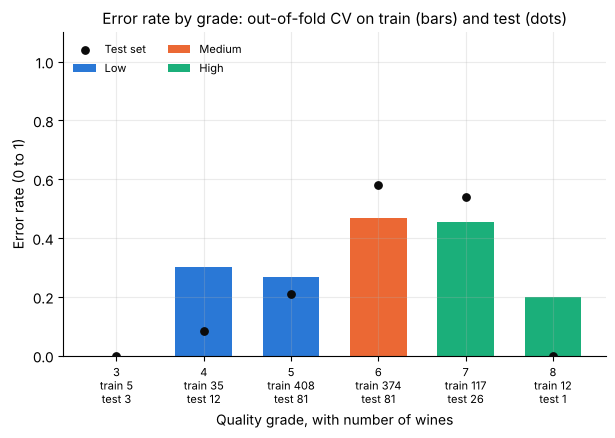


                               test  cv_oof_train_pooled
n                           204.000             4755.000
n_marginal                   74.000             1795.000
share_marginal                0.363                0.377
acc_marginal                  0.473                0.511
acc_confident                 0.692                0.706
share_marginal_true_medium    0.527                0.479
share_marginal_pred_medium    0.459                0.520

Summary: out-of-fold error by grade (grades with at least 20 training wines): grade 4 30%, grade 5 27%, grade 6 47%, grade 7 45%; the hardest is grade 6. 36% of test wines are marginal (m < 0.2), with accuracy 47% vs 69% for confident wines (CV pooled: 51% vs 71%).
Total runtime: 11.2 min


In [11]:
# ---- Error rate by quality grade (out-of-fold on train, pooled over 5 repeats, and test) ----
g_rep = [error_by_grade(q_tr, y_tr, oof_rf[r].argmax(axis=1))["error_rate"] for r in range(N_REPEATS)]
by_grade = pd.DataFrame({"class": [GRADE_CLASS[g] for g in GRADES],
                         "n_train": pd.Series(q_tr).value_counts().reindex(GRADES, fill_value=0).to_numpy(),
                         "error_cv_mean": pd.concat(g_rep, axis=1).mean(axis=1).to_numpy(),
                         "error_cv_sd_over_repeats": pd.concat(g_rep, axis=1).std(axis=1).to_numpy()}, index=GRADES)
t = error_by_grade(q_te, y_te, P_te.argmax(axis=1))
by_grade["n_test"], by_grade["error_test"] = t["n"].fillna(0).astype(int).to_numpy(), t["error_rate"].to_numpy()
by_grade.index.name = "grade"
save_table(by_grade.round(4), "rf_step6_error_by_grade.csv")
print(by_grade.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 4.2))
xg = np.arange(len(GRADES))
for i, g in enumerate(GRADES):
    ax.bar(i, by_grade.loc[g, "error_cv_mean"], width=0.65, color=CLASS_COLORS[GRADE_CLASS[g]],
           label=GRADE_CLASS[g] if GRADE_CLASS[g] not in ax.get_legend_handles_labels()[1] else None)
ok = by_grade["n_test"] > 0
ax.scatter(xg[ok], by_grade.loc[ok, "error_test"], color="#0b0b0b", zorder=3, s=28, label="Test set")
ax.set_xticks(xg, [f"{g}\ntrain {by_grade.loc[g, 'n_train']}\ntest {by_grade.loc[g, 'n_test']}" for g in GRADES], fontsize=8)
ax.set_ylim(0, 1.1); ax.set_xlabel("Quality grade, with number of wines"); ax.set_ylabel("Error rate (0 to 1)")
ax.set_title("Error rate by grade: out-of-fold CV on train (bars) and test (dots)")
ax.legend(frameon=False, loc="upper left", ncol=2, fontsize=8)
savefig(fig, "rf_step6_error_by_grade.png"); plt.show()

# ---- Marginal cases (team definition: margin p_top - p_second < 0.2) ----
mr, mbins = marginal_report(y_te, P_te)
mr_cv, mbins_cv = marginal_report(np.tile(y_tr, N_REPEATS), oof_rf.reshape(-1, 3))
save_table(pd.DataFrame({"test": mr, "cv_oof_train_pooled": mr_cv}).round(4), "rf_step6_marginal_summary.csv")
save_table(pd.concat({"test": mbins, "cv_oof_train_pooled": mbins_cv}, axis=1).round(4), "rf_step6_marginal_bins.csv")
print("\n" + pd.DataFrame({"test": mr, "cv_oof_train_pooled": mr_cv}).round(3).to_string())
worst = by_grade.loc[by_grade["n_train"] >= 20, "error_cv_mean"].sort_values(ascending=False)
print(f"\nSummary: out-of-fold error by grade (grades with at least 20 training wines): "
      + ", ".join(f"grade {g} {by_grade.loc[g, 'error_cv_mean']:.0%}" for g in worst.sort_index().index)
      + f"; the hardest is grade {worst.index[0]}. {mr['share_marginal']:.0%} of test wines are marginal (m < 0.2), with accuracy "
      f"{mr['acc_marginal']:.0%} vs {mr['acc_confident']:.0%} for confident wines (CV pooled: {mr_cv['acc_marginal']:.0%} vs {mr_cv['acc_confident']:.0%}).")
print(f"Total runtime: {(time.time() - T_START) / 60:.1f} min")

In [12]:
# Numbers to quote in Q&A (all computed above; nothing new is fitted here)
quote = {"test fingerprint": fingerprint, "best params": best_params,
         "CV macro-F1, RF tuned (mean)": cv_rf["macro_f1"].mean(), "CV macro-F1, RF tuned (SD)": cv_rf["macro_f1"].std(),
         "CV macro-F1, majority baseline": cv_dummy["macro_f1"].mean(),
         "train macro-F1": train_res["macro_f1"], "train - CV macro-F1 gap": gap_f1,
         "top feature (permutation)": top.index[0], "tuned - default CV macro-F1": p_tune["mean_diff"],
         "test macro-F1": test_res.loc["Random Forest", "macro_f1"], "test QWK": test_res.loc["Random Forest", "qwk"],
         "test log loss": test_res.loc["Random Forest", "log_loss"],
         "High recall, CV mean": recall_tab.loc["High", "recall_cv_mean"], "test share marginal": mr["share_marginal"]}
for k, v in quote.items():
    print(f"{k:38s} {v:.4g}" if isinstance(v, (float, np.floating)) else f"{k:38s} {v}")

test fingerprint                       a963514c99
best params                            {'max_depth': None, 'min_samples_leaf': 5, 'max_features': 0.5, 'class_weight': 'balanced_subsample'}
CV macro-F1, RF tuned (mean)           0.6047
CV macro-F1, RF tuned (SD)             0.04504
CV macro-F1, majority baseline         0.2135
train macro-F1                         0.8926
train - CV macro-F1 gap                0.2879
top feature (permutation)              alcohol
tuned - default CV macro-F1            0.009679
test macro-F1                          0.5577
test QWK                               0.5578
test log loss                          0.7715
High recall, CV mean                   0.5699
test share marginal                    0.3627
